## 测试不同视频采样方法

In [1]:
%matplotlib inline

import cv2
import numpy as np
import matplotlib.pyplot as plt
import math
from PIL import Image
from pathlib import Path
VIDEO_PATH = Path("data/practice_data/videos/train_part1/1-cvpr-2025.mp4")

if not VIDEO_PATH.exists():
    raise FileExistsError(VIDEO_PATH)

## 均匀采样

In [2]:
def uniform_sample(
        path,
        num_frames = 32,
):

    if num_frames < 1:
        ValueError("num_frames 必须大于 0！")

    cap = cv2.VideoCapture(path)

    if not cap.isOpened():
        raise FileNotFoundError(path)


    frames = []
    try:
        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        if total_frames < num_frames:
            print("视频没有有效帧")

        frames_indices = np.linspace(
            0, total_frames - 1, min(total_frames,num_frames), dtype=int
        )

        for index in frames_indices:
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(index))

            success, frame = cap.read()
            if not success:
                raise IOError(f'Cannot read frame {index} in  {path}')

            frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))


    finally:
        cap.release()

    visualize_frames(frames)

    return [Image.fromarray(frame) for frame in frames]


In [3]:
def visualize_frames(frames):
    if not frames:
        raise ValueError("没有可显示的视频帧")

    num_rows = math.ceil(len(frames) / 4)

    fig, axes = plt.subplots(
        num_rows, 4,
        figsize=(16, 3 * num_rows),
        squeeze=False,
    )

    # 包括没有图片的空白格子，也关闭坐标轴
    for ax in axes.flat:
        ax.axis("off")

    for i, (frame, ax) in enumerate(zip(frames, axes.flat)):
        ax.imshow(frame)
        ax.set_title(f"Sample {i + 1}")

    plt.tight_layout()
    plt.show()

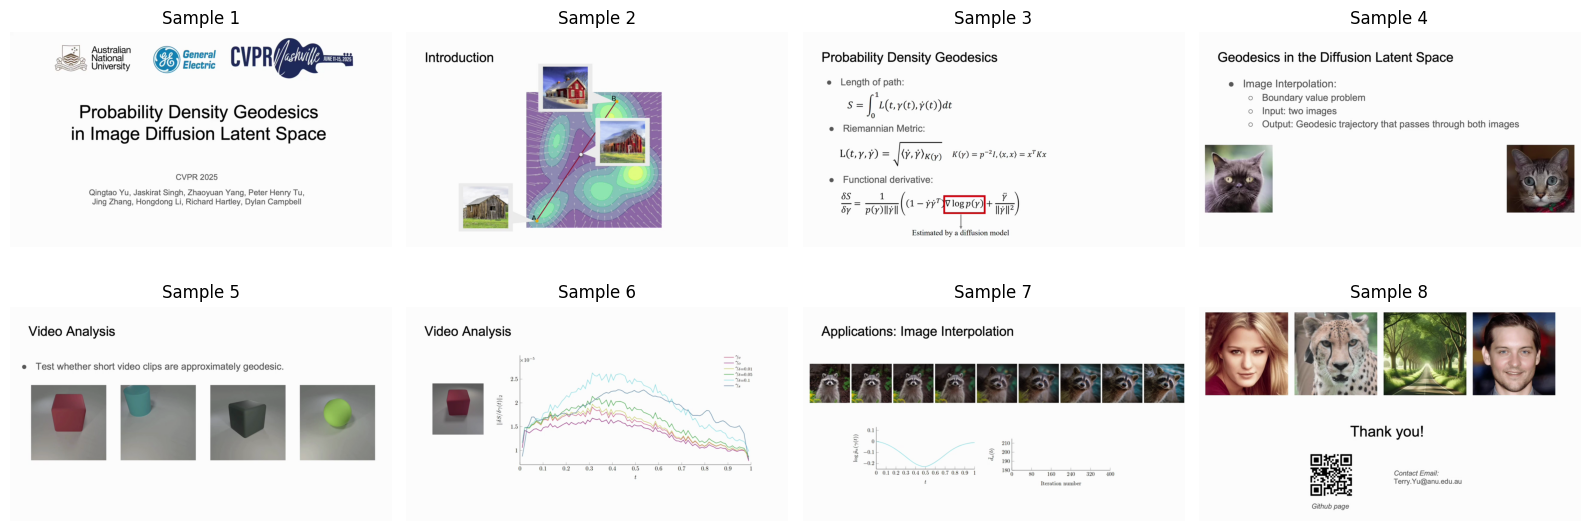

[<PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>]

In [4]:
uniform_sample(VIDEO_PATH,8)

## 随机采样

In [5]:
def random_sample(
    path,
    num_frames = 32,
    random_seed = None
):
    if num_frames < 1:
        ValueError("num_frames 必须大于 0！")
    cap = cv2.VideoCapture(path)
    if not cap.isOpened():
        raise FileNotFoundError(path)

    frames = []
    try:
        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        if total_frames < num_frames:
            print("视频帧数小于采样帧数，结果一定会提取重复帧数!")

        if random_seed is not None:
            np.random.seed(random_seed)

        frames_indices = np.random.randint(
            0,total_frames - 1, num_frames,dtype=int
        )

        for index in frames_indices:
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(index))

            success, frame = cap.read()
            if not success:
                raise IOError(f'Cannot read frame {index} in  {path}')
            frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))

    finally:
        cap.release()

    visualize_frames(frames)
    return [Image.fromarray(frame) for frame in frames]




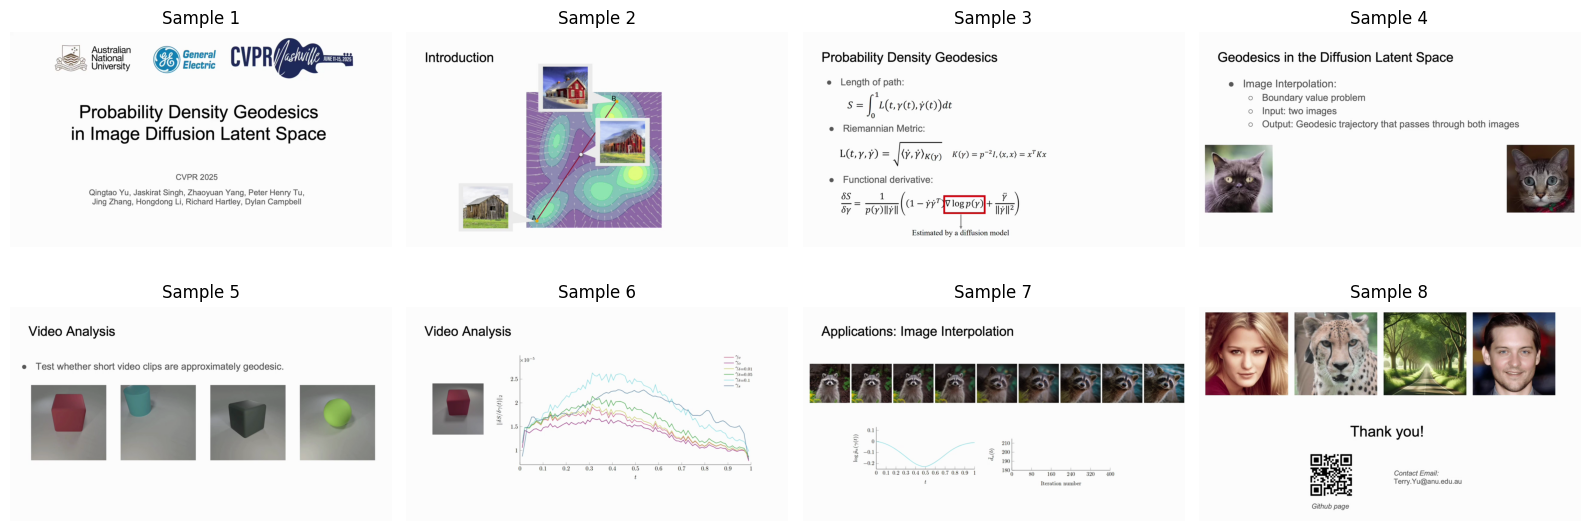

--------------------------------------------------------------------------------------------------------------


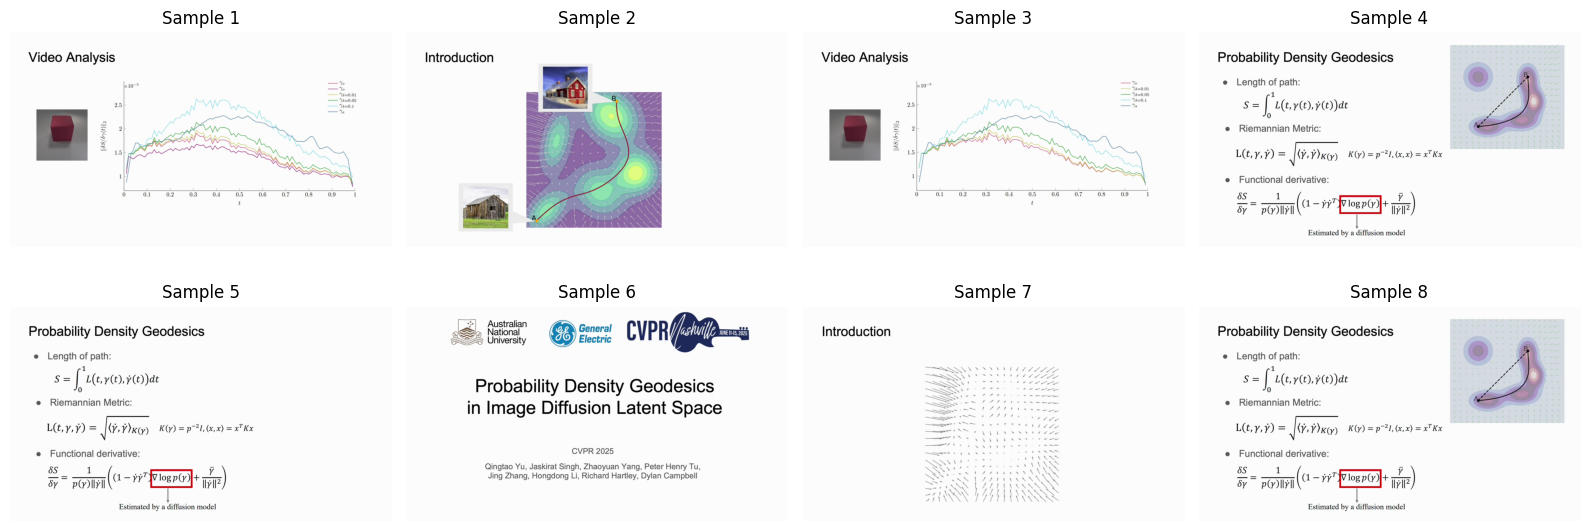

[<PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>]

In [6]:
uniform_sample(VIDEO_PATH,8)
print('-'*110)
random_sample(VIDEO_PATH,8)

## 按照画面变化程度采样

检测明显画面变化，把视频分成若干段，每段取稳定的代表帧

In [ ]:
def read_candidates(video_path, interval=1.0):
    """每隔 interval 秒读取一帧，返回时间戳和 RGB 图像。"""
    if interval <= 0:
        raise ValueError("interval 必须大于 0")

    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise IOError(f"无法打开视频：{video_path}")

    timestamps = []
    frames = []

    try:
        fps = cap.get(cv2.CAP_PROP_FPS)
        total_frames = cap.get(cv2.CAP_PROP_FRAME_COUNT)

        if fps <= 0 or total_frames <= 0:
            raise ValueError("无法获取有效的视频时长")

        duration = total_frames / fps

        for t in np.arange(0, duration, interval):
            cap.set(cv2.CAP_PROP_POS_MSEC, float(t * 1000))
            success, frame = cap.read()

            if not success:
                continue

            timestamps.append(float(t))
            frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))

    finally:
        cap.release()

    if not frames:
        raise ValueError("未读取到有效帧")


    # visualize_frames(frames) # debug
    return np.array(timestamps), frames

In [8]:
imgs,timestamps = read_candidates(VIDEO_PATH,1)
print(len(imgs))
print(len(timestamps))

295
295


### 计算相邻帧的变化程度
先使用容易理解的“平均像素差”：对应位置的像素差取绝对值，再求平均。
$$
d_i=\frac{1}{HW}\sum_{x,y}
\left|I_i(x,y)-I_{i-1}(x,y)\right|
$$

在实际实现中，计算前把图片缩小、转成灰度并轻微模糊，可以减少计算量，也能减弱细小噪声的影响。

In [9]:
def prepare_frame(frame):
    small = cv2.resize(frame, (160, 90))
    gray = cv2.cvtColor(small, cv2.COLOR_RGB2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    # 转成浮点数，避免 uint8 相减溢出
    return blurred.astype(np.float32) / 255.0


def calculate_changes(frames):
    features = [prepare_frame(frame) for frame in frames]
    changes = np.zeros(len(features))

    for i in range(1, len(features)):
        changes[i] = np.abs(features[i] - features[i - 1]).mean()

    return changes

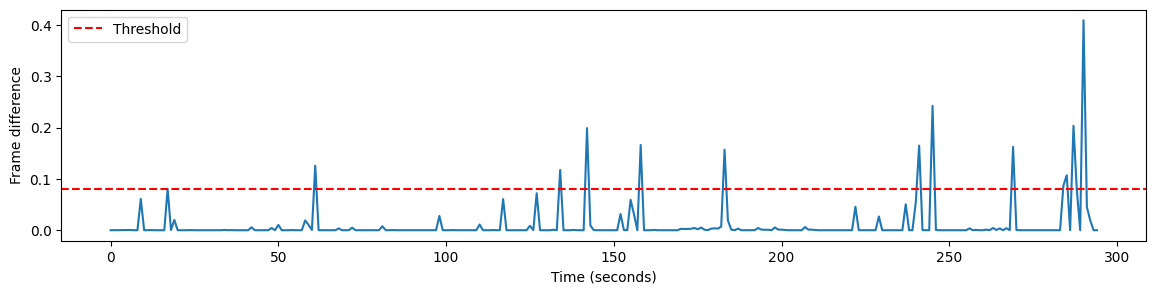

In [10]:
timestamps, frames = read_candidates(VIDEO_PATH, interval=1.0)
changes = calculate_changes(frames)

threshold = 0.08  # 只是起始尝试值，不是通用阈值

plt.figure(figsize=(14, 3))
plt.plot(timestamps, changes)
plt.axhline(threshold, color="red", linestyle="--", label="Threshold")
plt.xlabel("Time (seconds)")
plt.ylabel("Frame difference")
plt.legend()
plt.show()

### 根据阈值分段

由于实际中选取的片段 M 可能大于或小于需要固定的帧数 K (num_frames)

我们做以下规定:

|情况|处理方式|
|---|---|
|M=K	|每段取一张中间帧|
|M>K	|合并变化较小的相邻片段，直到剩下 \(K\) 段，再每段取一帧|
|M<K	|每段先分配一帧，把剩余额度分给时间覆盖最稀疏的片段|


In [11]:
def detect_boundaries(timestamps, changes,
                      threshold=0.08, min_scene_seconds=3.0):
    """返回片段边界，包含起点 0 和终点 len(timestamps)。"""
    boundaries = [0]

    for i in range(1, len(timestamps)):
        elapsed = timestamps[i] - timestamps[boundaries[-1]]

        if changes[i] > threshold and elapsed >= min_scene_seconds:
            boundaries.append(i)

    boundaries.append(len(timestamps))
    return boundaries

def allocate_frames(timestamps, changes, boundaries, k):
    """返回调整后的边界和各片段的帧数配额。"""
    if k <= 0:
        raise ValueError("k 必须大于 0")

    n = len(timestamps)
    if n == 0:
        raise ValueError("候选帧不能为空")

    # 总候选不足时，返回全部，不重复帧
    target = min(k, n)
    boundaries = list(boundaries)

    # 情况一：片段过多，删除较弱的内部边界
    if len(boundaries) - 1 > target:
        internal = boundaries[1:-1]

        # 差异降序；差异相同时，较早的边界优先
        strongest = sorted(
            internal,
            key=lambda i: (-float(changes[i]), i),
        )[:target - 1]

        boundaries = [0, *sorted(strongest), n]

    starts = np.array(boundaries[:-1], dtype=int)
    ends = np.array(boundaries[1:], dtype=int)

    # 每段拥有多少张候选帧
    capacities = ends - starts

    # 末段没有下一个边界时间，用典型候选间隔估计末端
    interval = float(np.median(np.diff(timestamps))) if n > 1 else 1.0
    end_times = np.array([
        timestamps[end] if end < n else timestamps[-1] + interval
        for end in ends
    ])
    durations = end_times - timestamps[starts]

    # 每段至少一帧
    counts = np.ones(len(starts), dtype=int)
    remaining = target - int(counts.sum())

    # 情况二：还有额度，补给当前时间覆盖最稀疏的片段
    for _ in range(remaining):
        scores = durations / counts

        # 候选帧已经用完的片段不能继续分配
        scores[counts >= capacities] = -np.inf

        chosen = int(np.argmax(scores))
        counts[chosen] += 1

    return boundaries, counts



def select_from_segments(boundaries, counts):
    """按各段配额取候选帧索引，结果有序且不重复。"""
    selected = []

    for start, end, count in zip(
        boundaries[:-1], boundaries[1:], counts
    ):
        size = end - start

        # 把本段分为 count 个小区间，取各区间中心
        offsets = (
            (np.arange(count) + 0.5) * size / count
        ).astype(int)

        selected.extend((start + offsets).tolist())

    return np.array(selected, dtype=int)



In [19]:
def scene_sample(
    path,
    num_frames,
    threshold=0.08,
    interval=1.0,
    min_scene_seconds=3.0,
):
    """
    path: 视频路径
    num_frames: 目标帧数；候选不足时返回全部候选
    threshold: 相邻候选帧的画面变化阈值
    interval: 候选帧的采样时间间隔，单位秒
    min_scene_seconds: 检测分段时，相邻分段起点的最小间隔
    """
    if not isinstance(num_frames, (int, np.integer)) or num_frames <= 0:
        raise ValueError("num_frames 必须是正整数")

    # 按前面 read_candidates 的返回顺序
    timestamps, frames = read_candidates(path, interval)

    # 内部已经逐张进行缩放、灰度化等处理；
    # 原始 RGB frames 不会被替换
    changes = calculate_changes(frames)

    timestamps = np.asarray(timestamps, dtype=float)
    changes = np.asarray(changes, dtype=float)

    original_boundaries = detect_boundaries(
        timestamps,
        changes,
        threshold=threshold,
        min_scene_seconds=min_scene_seconds,
    )

    final_boundaries, counts = allocate_frames(
        timestamps,
        changes,
        original_boundaries,
        num_frames,
    )

    indices = select_from_segments(final_boundaries, counts)

    final_frames = [frames[i] for i in indices]

    visualize_frames(final_frames)

    return [Image.fromarray(frame) for frame in final_frames]

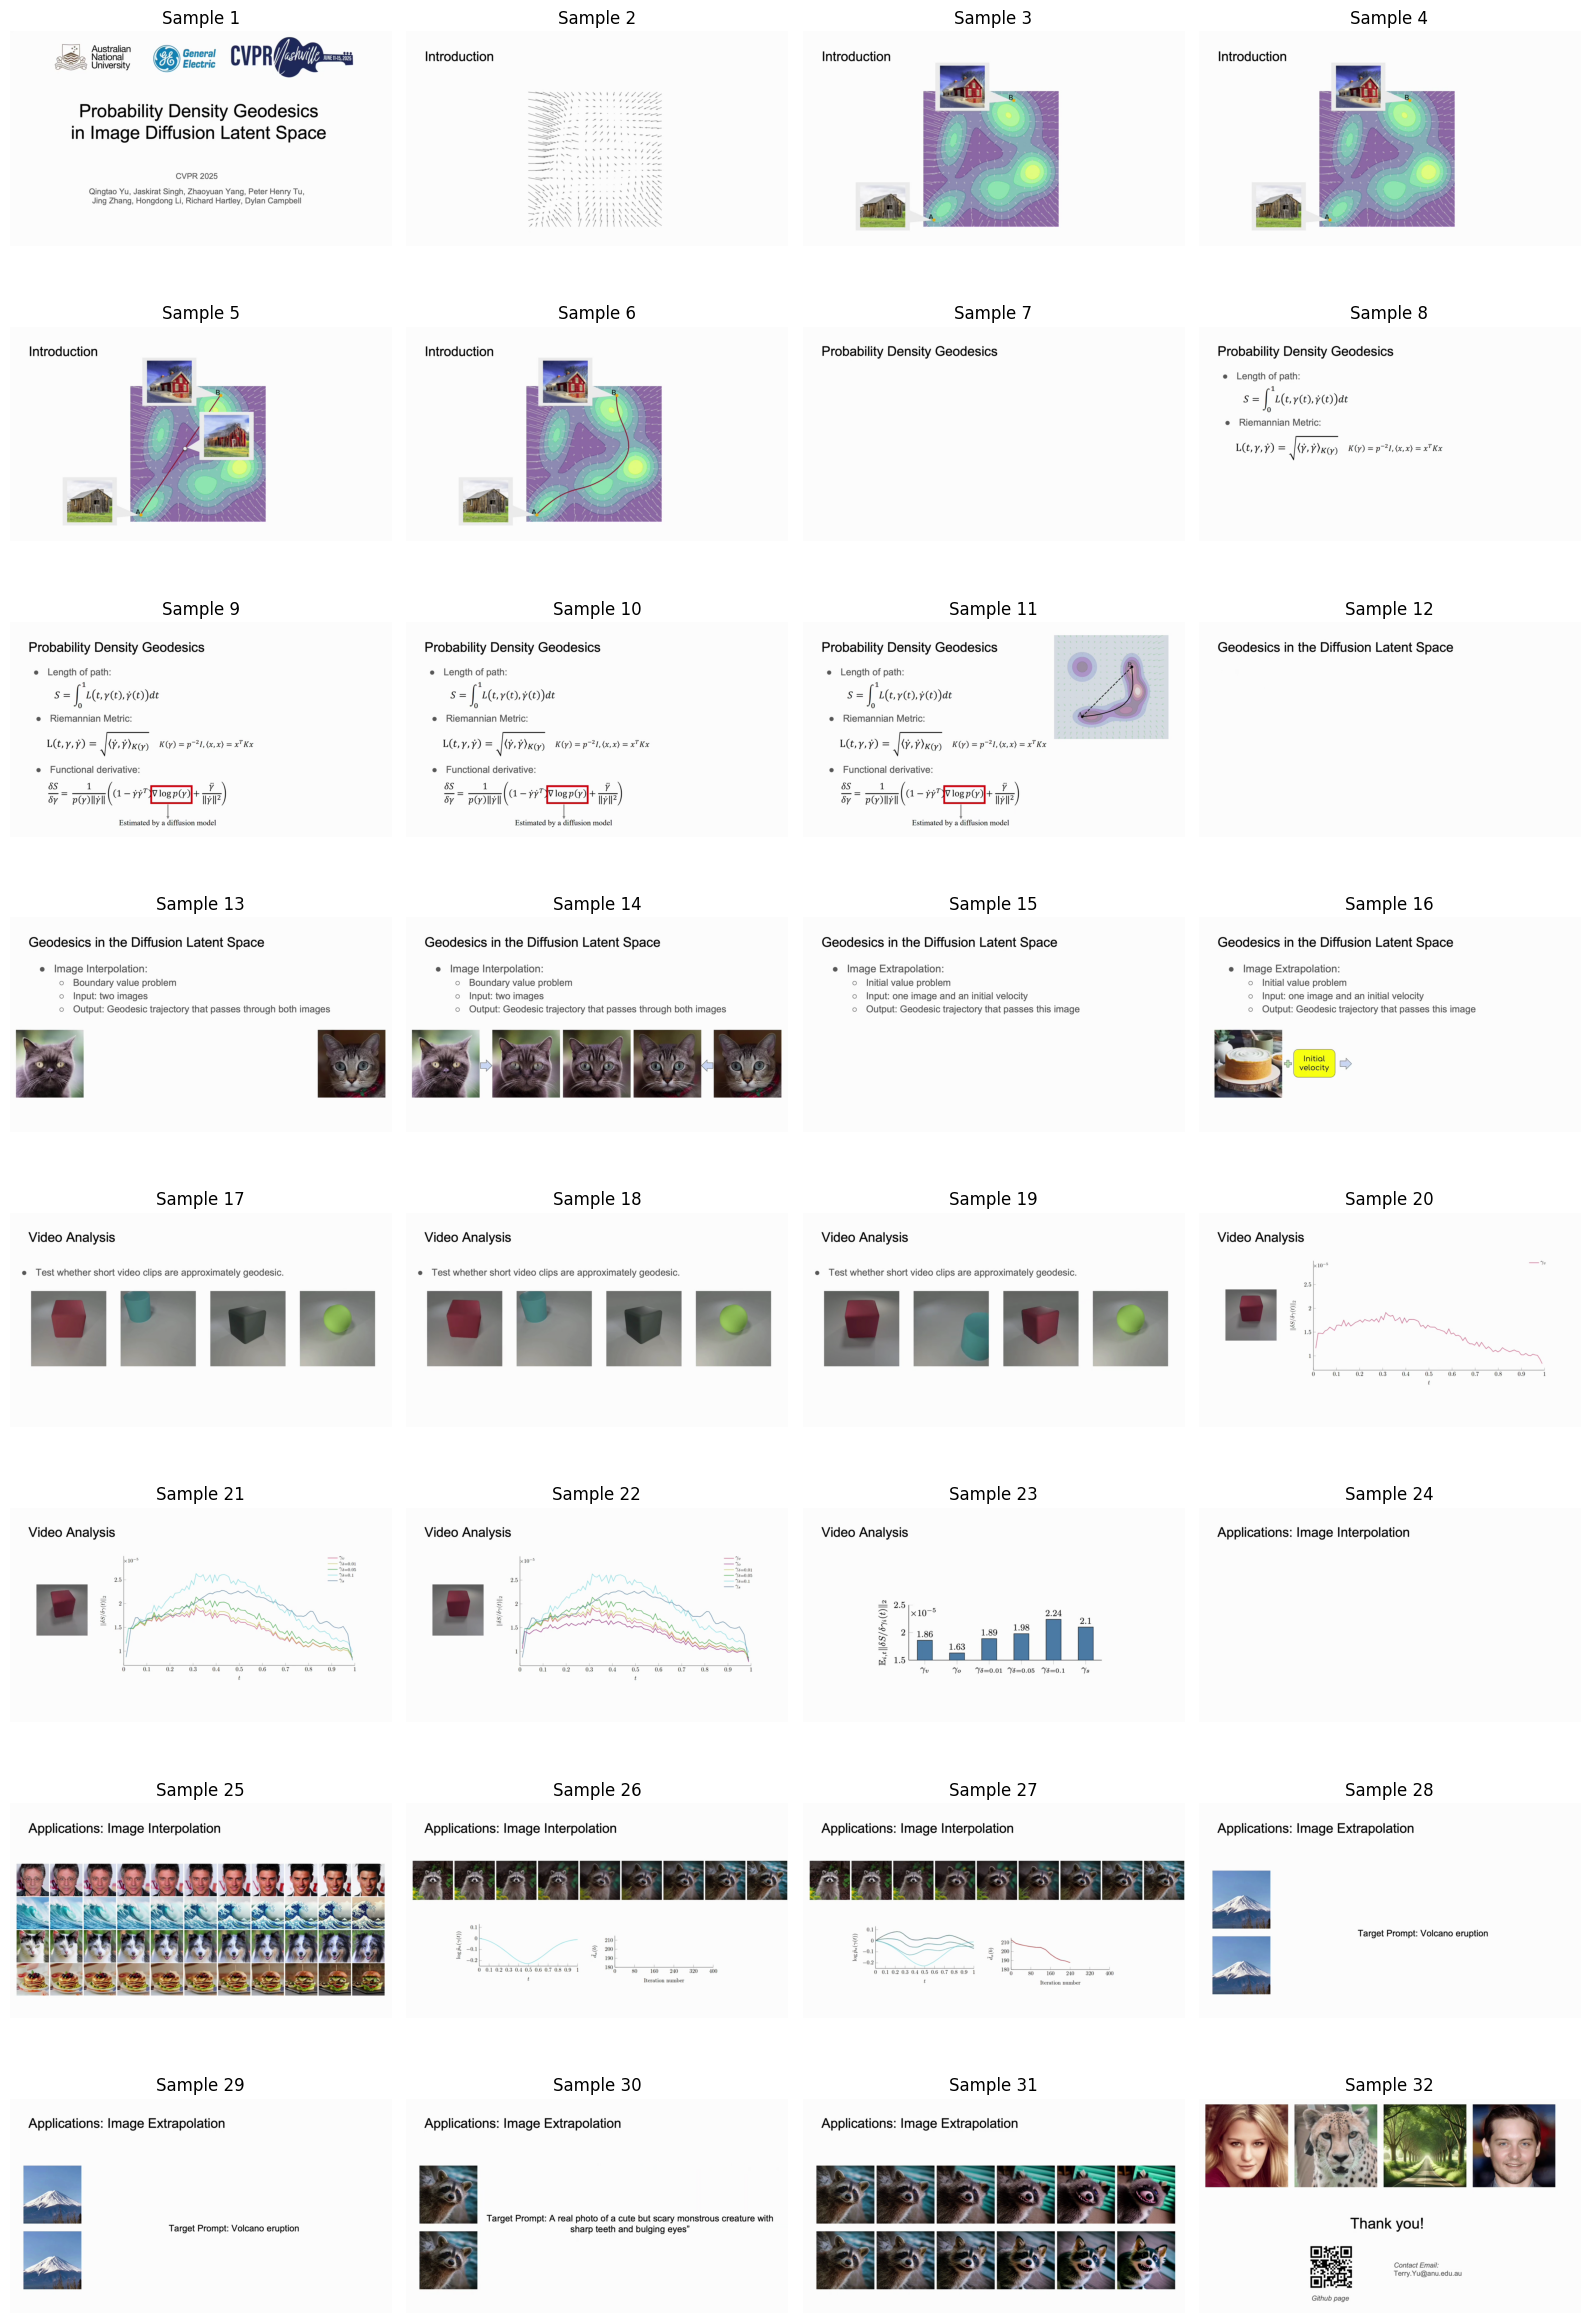

In [21]:
scene_frames = scene_sample(
    VIDEO_PATH,
    32
)


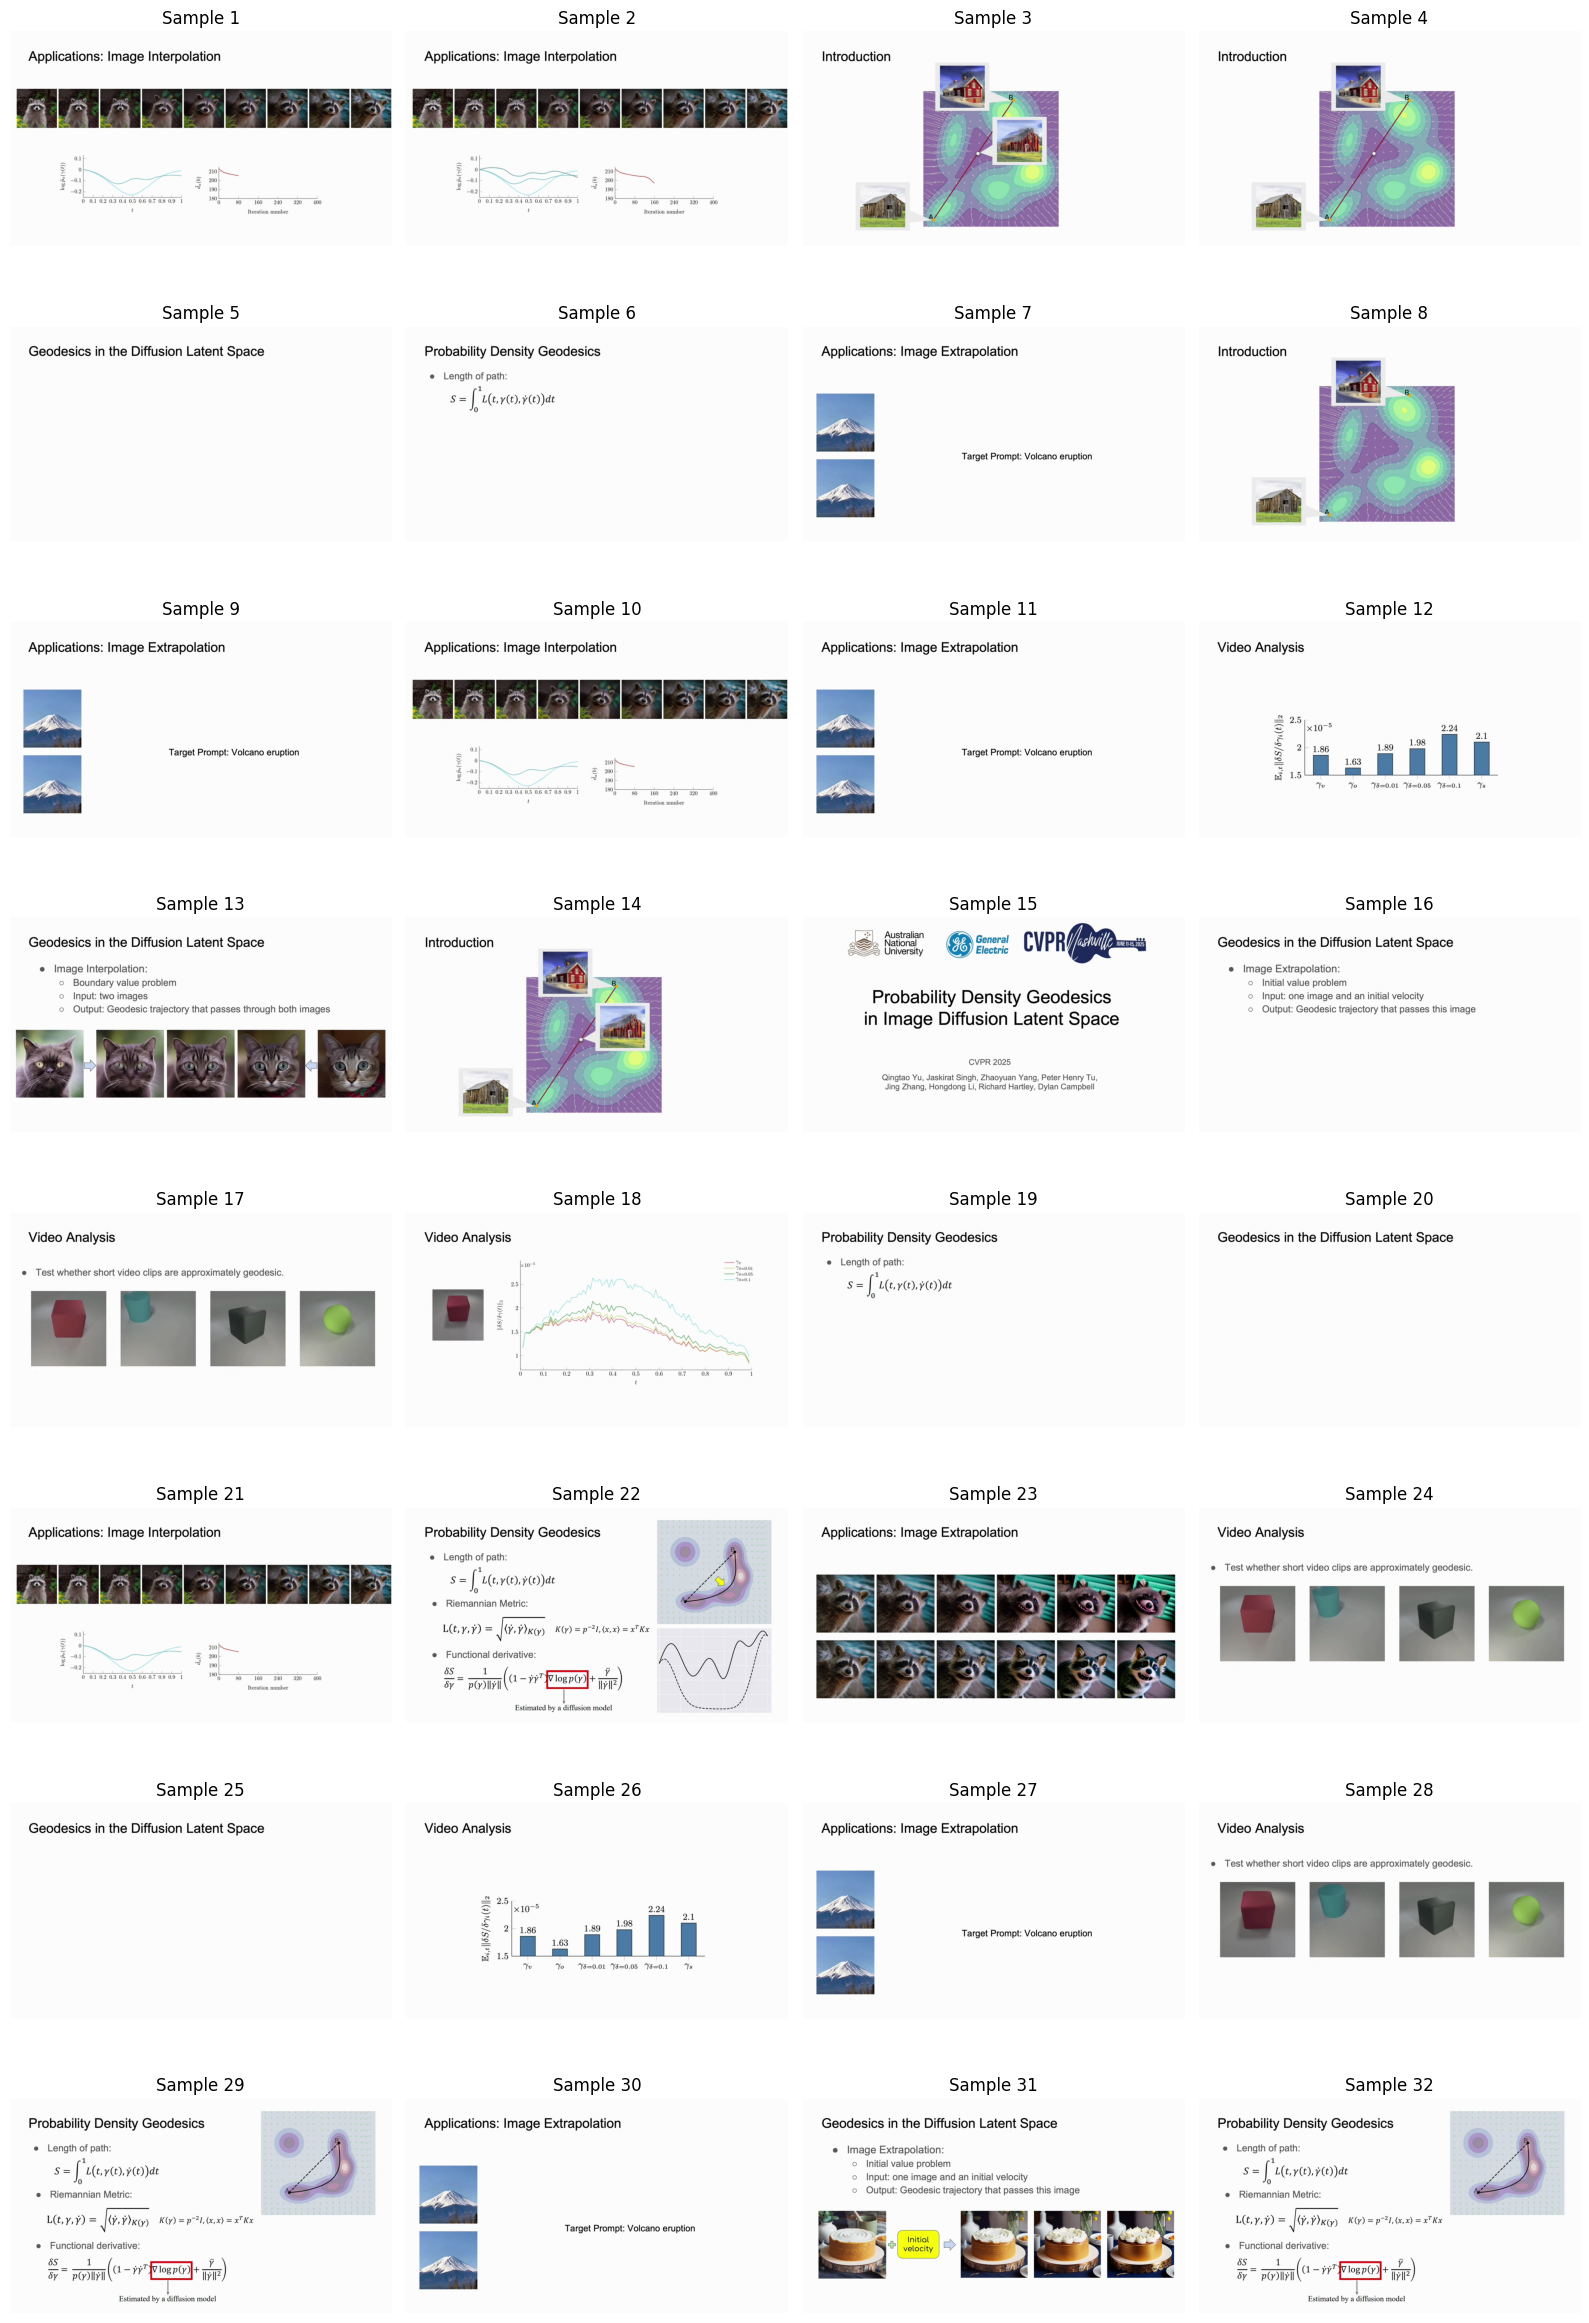

[<PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image im

In [22]:
random_sample(VIDEO_PATH,32)

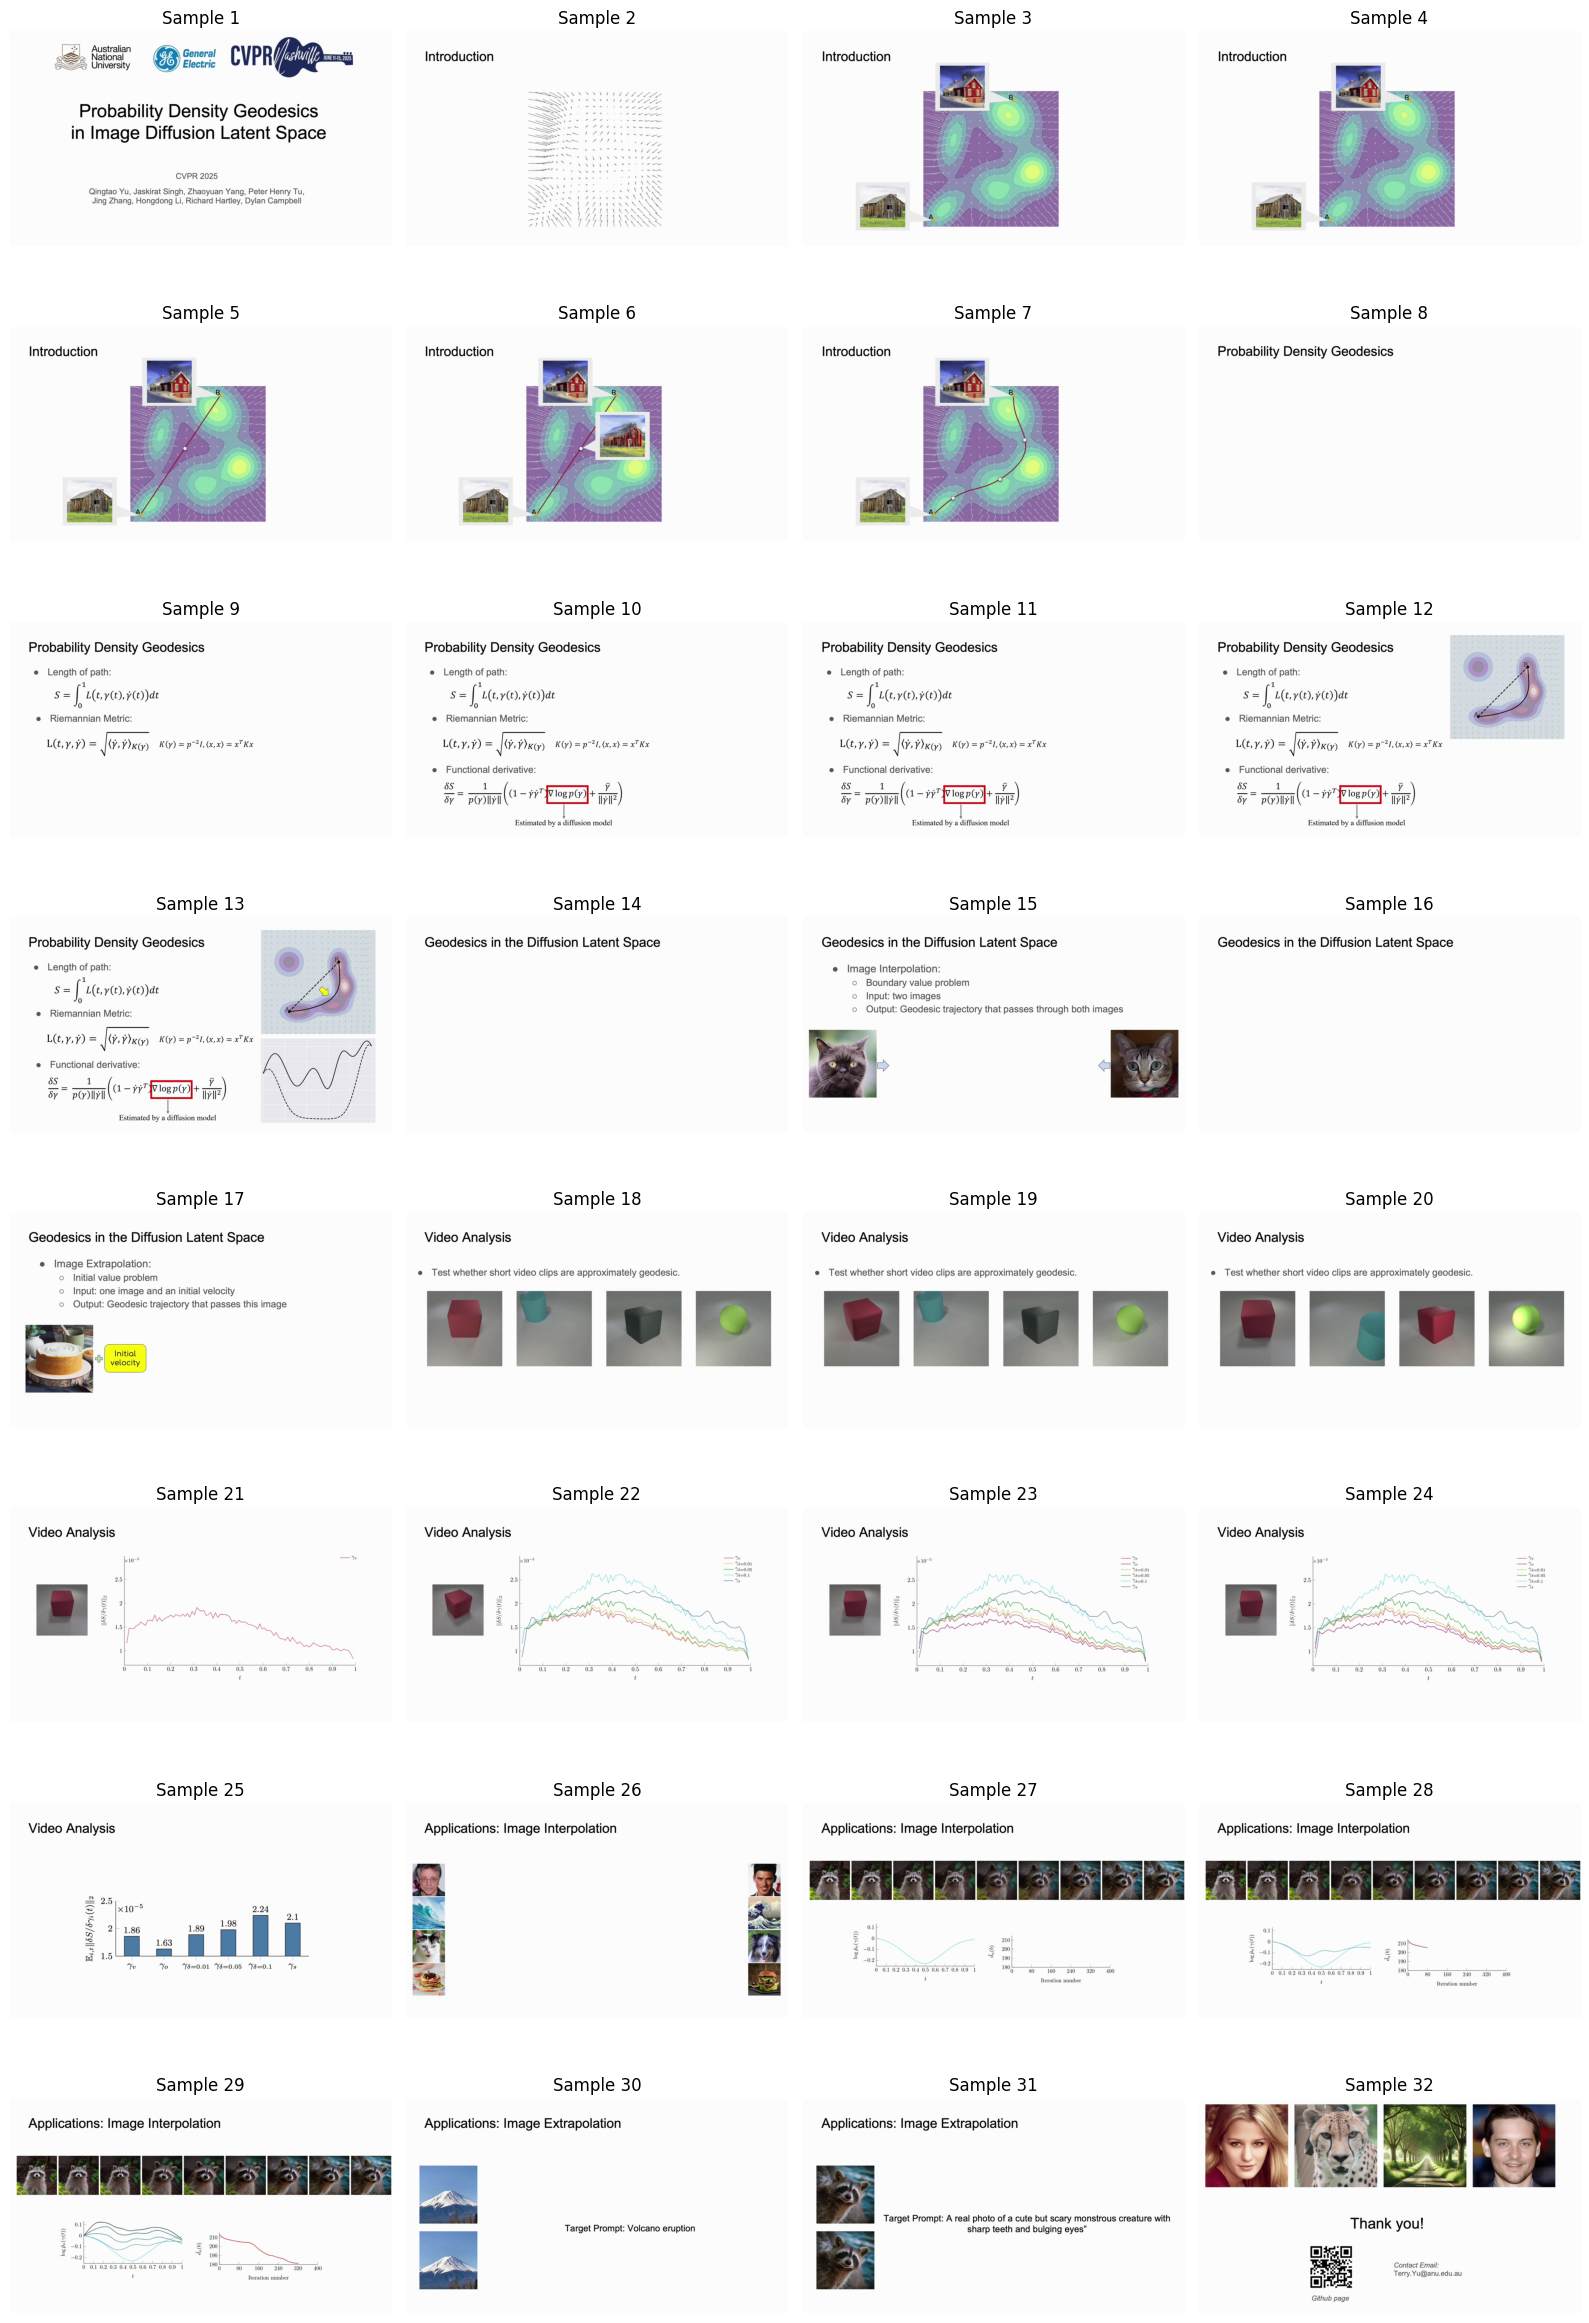

[<PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image image mode=RGB size=1280x720>,
 <PIL.Image.Image im

In [23]:
uniform_sample(VIDEO_PATH,32)